# Blast Fragmentation & Cost
**Brandon Kazangarare** · Mining Engineering, Central South University

**Question:** for a given rock, which blast design gives fine enough rock (median fragment size X50 ≤ 30 cm, with few boulders) at the lowest cost per m³?

**Data:** 110 real production blasts from 10 mines and quarries in Spain, Turkey, India, Indonesia and the USA (Hudaverdi, Kulatilake & Kuzu, 2011), with two transcription errors corrected against Kulatilake et al. (2010).

### Approach
| Part | Steps | What it does |
|---|---|---|
| **A · Machine learning** | 1–4 | Predict X50 from blast design and rock properties, test the models honestly, and explain them with SHAP |
| **B · Physics + cost** | 5–8 | Calibrate the Kuz-Ram fragmentation model to each mine, cost every design, find the cheapest design that meets the targets, and test how sensitive the answer is |

**Why two parts:** Step 2 shows that, inside a single mine, the data cannot tell how much explosive changes fragment size, because engineers load more explosive where they expect tough rock. Machine learning can explain *what matters*; the cost *decision* uses Kuz-Ram physics calibrated to each mine's real blasts.

## Setup
**Libraries.** `numpy` and `pandas` handle the numbers and tables, `matplotlib` draws the plots, `scipy` gives the Spearman correlation, and `scikit-learn` provides the models, the cross-validation and the error scores.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor

**Three input files**

| File | Contents |
|---|---|
| `blast_master_110.csv` | One row per blast: design ratios, powder factor, rock properties and the measured X50 |
| `rock_types.csv` | The three rock classes used for recommendations: Soft = Akdaglar sandstone, Medium = Mrica andesite, Hard = Murgul dacite, each with its typical design and bench height |
| `cost_assumptions.csv` | Prices and design assumptions (hole diameter, explosive, targets), kept in one file so they can be changed in one place |

In [2]:
DATA = "../data/"        # in Google Colab: upload the three CSVs and set DATA = "/content/"
RESULTS = "../results/"  # in Colab: RESULTS = ""

df = pd.read_csv(DATA + "blast_master_110.csv")
rocks = pd.read_csv(DATA + "rock_types.csv")
assume = pd.read_csv(DATA + "cost_assumptions.csv")

**Model inputs and target.** The dataset describes each blast with ratios, so blasts of different sizes can be compared.

| Column | Meaning | Unit |
|---|---|---|
| `S_B` | spacing ÷ burden | – |
| `H_B` | bench height ÷ burden | – |
| `B_D` | burden ÷ hole diameter | – |
| `T_B` | stemming ÷ burden | – |
| `Pf` | powder factor: explosive per m³ of rock | kg/m³ |
| `XB` | in-situ block size of the rock mass | m |
| `E` | elastic modulus (rock stiffness) | GPa |
| **`X50`** | **target: median fragment size after the blast** | m |

In [3]:
FEATURES = ["S_B", "H_B", "B_D","T_B","Pf", "XB", "E"]
TARGET = "X50"

**Assumptions as a dictionary.** Each row of `cost_assumptions.csv` becomes an entry in `A`, so later code reads `A["drilling_cost"]` instead of a hard-coded number. Every value is in the unit printed next to it; the targets are in **metres** to match `X50`.

The hole diameter (102 mm) is an assumption: the dataset gives ratios only, so one diameter is needed to turn them back into metres.

In [4]:
A = {r.parameter: (float(r.value) if r.parameter != "explosive" else r.value)for r in assume.itertuples()}
print(assume[["parameter", "value", "unit"]].to_string(index=False))

           parameter value     unit
       hole_diameter   102       mm
           explosive  ANFO        -
   explosive_density   850    kg/m3
       explosive_RWS   100        -
     explosive_price   1.0   USD/kg
       drilling_cost    15    USD/m
accessories_per_hole    15 USD/hole
      subdrill_ratio   0.3      J/B
          target_X50  0.30        m
      oversize_limit   1.0        m
        max_oversize     5        %
 drilling_accuracy_W   0.2        m


## Step 1 · Load and check the data
**What this does:** prints the table size and missing values, counts blasts per site, summarises every column, and counts how many different values each column takes **inside each mine**.

**Why:** a model can only learn from what varies. If a value never changes inside a mine, it can tell mines apart but cannot explain individual blasts.

In [5]:
print(df.shape, "| missing:", df.isna().sum().sum())
print(df.site.value_counts())
print(df[FEATURES + [TARGET]].describe().round(2))
print(df.groupby("site")[FEATURES + [TARGET]].nunique())

(110, 16) | missing: 0
site
Akdaglar         25
Enusa            13
Mrica            12
Reocin           10
Dongri-Buzurg    10
Murgul            9
Ozmert            9
Soma              8
Reocin-UG         7
Miami             7
Name: count, dtype: int64
          S_B     H_B     B_D     T_B      Pf      XB       E     X50
count  110.00  110.00  110.00  110.00  110.00  110.00  110.00  110.00
mean     1.18    3.34   27.41    1.26    0.54    1.09   29.17    0.30
std      0.11    1.60    4.94    0.67    0.24    0.53   17.82    0.18
min      1.00    1.33   17.98    0.50    0.22    0.02    9.57    0.02
25%      1.13    2.07   24.72    0.83    0.35    0.69   15.00    0.17
50%      1.20    2.82   27.27    1.11    0.48    1.03   16.90    0.23
75%      1.25    4.69   30.30    1.40    0.69    1.52   45.00    0.40
max      1.75    6.82   39.47    4.67    1.26    2.35   60.00    0.96
               S_B  H_B  B_D  T_B  Pf  XB  E  X50
site                                             
Akdaglar        

**Findings**
- 110 blasts, no missing values, 10 sites (Akdaglar has 25 blasts; Miami and Reocin-UG only 7).
- X50 ranges from 2 cm to 96 cm (median 23 cm), so a 30 cm target sits inside the data.
- **E has one value per site.** Rock stiffness is measured once per mine, so it acts as a *mine fingerprint*.
- Some mines barely change their design: Enusa uses one geometry for all 13 blasts; Soma one powder factor for all 8.
- Stemming ratios above 3 (up to 4.67) all come from Reocin-UG, the only underground site.

## Step 2 · Explore: does more explosive give smaller rock?
Blasting theory (Kuz-Ram) says median fragment size falls as powder factor rises:

$$X_{50} \;\propto\; P_f^{-0.8}$$

**What this does:** plots powder factor against X50 for every blast, coloured by mine, with one trend line through all blasts. It then measures the trend with the **Spearman correlation** ρ, first for all blasts and then mine by mine.

**Spearman ρ** ranks both variables and correlates the ranks: ρ = −1 means "always goes down", +1 "always goes up", 0 "no trend". It ignores the exact shape of the curve, which suits a power law.

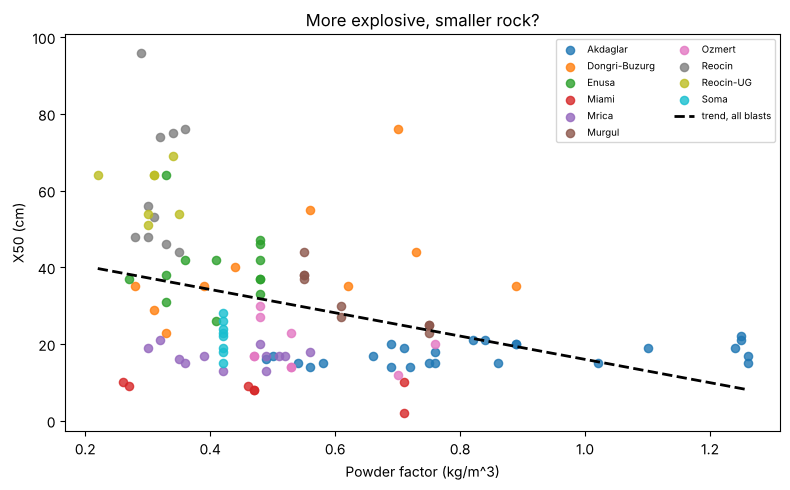

All blasts: rho(Pf, X50) = -0.41
 Akdaglar       rho =+0.41
 Dongri-Buzurg  rho =+0.56
 Enusa          rho =+0.10
 Miami          rho =-0.44
 Mrica          rho =-0.13
 Ozmert         rho =-0.31
 Reocin         rho =-0.02
 Reocin-UG      rho =+0.24


In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
for site, g in df.groupby("site"):
  ax.scatter(g.Pf, g.X50 * 100, label=site, s=35, alpha=0.8)
b, a = np.polyfit(df.Pf, df.X50 * 100, 1)
xs  = np.linspace(df.Pf.min(), df.Pf.max(), 50)
ax.plot(xs, a + b * xs, "k--", lw=2, label="trend, all blasts")
ax.set_xlabel("Powder factor (kg/m^3)"); ax.set_ylabel("X50 (cm)")
ax.set_title("More explosive, smaller rock?"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

print("All blasts: rho(Pf, X50) =", round(spearmanr(df.Pf, df.X50)[0], 2))
for site, g in df.groupby("site"):
  if g.Pf.nunique() > 3:
    print(f" {site:14s} rho ={spearmanr(g.Pf, g.X50)[0]:+.2f}")

**Findings**
- **All blasts together:** ρ = −0.41. More explosive goes with smaller rock, as physics predicts.
- **Mine by mine:** the sign flips. At Akdaglar (+0.41) and Dongri-Buzurg (+0.56), more explosive goes with *bigger* rock.

**Why:** this is **confounding**. Engineers do not choose powder factor at random: they load more explosive on blasts they expect to break badly. Inside a mine, a high powder factor often marks a difficult blast rather than causing big fragments.

**Consequence:** a model trained on this data cannot be trusted to say *how much* explosive to use. That decision is handed to calibrated physics in Part B.

## Step 3 · Models, tested two ways
**Five models**

| Model | Idea |
|---|---|
| Mean | Always predicts the average X50: the floor any model must beat |
| Log-linear | Kuz-Ram's power-law *shape*, with exponents fitted to the data (formula below) |
| Random forest | 500 decision trees averaged |
| Gradient boosting | Trees built one after another, each correcting the previous ones |
| Physics GBM | Gradient boosting **forced to follow blasting physics** (table below) |

The log-linear model takes logs of both sides of a power law, which turns it into a straight line:

$$\ln X_{50} = a + b_1 \ln(S/B) + b_2 \ln(H/B) + \dots + b_7 \ln E$$

The physics GBM uses **monotonic constraints** (`MONO`): a prediction may only move in the physically sensible direction as each input rises.

| Input | Constraint | Reason |
|---|---|---|
| `Pf` | −1 (X50 can only fall) | more explosive per m³ breaks rock finer |
| `B_D`, `T_B`, `XB` | +1 (X50 can only rise) | larger burden, longer stemming or blockier rock give coarser fragments |
| `S_B`, `H_B`, `E` | 0 (free) | direction not fixed by theory |

**Two tests**, both using cross-validation, so that every blast is predicted by a model that never saw it:
- **Known mines:** 5-fold random cross-validation. New blasts at mines the model has seen, like a mine calibrating on its own records.
- **Unseen mine:** leave-one-site-out (`GroupKFold` by site). Every blast of one mine is held out at a time, like using the model at a brand-new mine.

**Scores**

$$R^2 = 1 - \frac{\sum (y - \hat{y})^2}{\sum (y - \bar{y})^2} \qquad\qquad \mathrm{MAE} = \frac{1}{n}\sum \lvert y - \hat{y} \rvert$$

R² compares the model with always guessing the average: 1 is perfect, 0 is no better than the average, and **negative is worse than the average**. MAE is the typical miss, reported in centimetres.

In [7]:
X, y, groups = df[FEATURES], df[TARGET], df["site"]

MONO = {"S_B": 0, "H_B": 0, "B_D": 1, "T_B": 1, "Pf": -1, "XB": 1, "E":0}

models = {
    "mean": DummyRegressor(),
    "log-linear": TransformedTargetRegressor(
        regressor =make_pipeline(FunctionTransformer(np.log), LinearRegression()),
        func=np.log, inverse_func=np.exp),
    "random forest": RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=0),
    "gradient boosting": GradientBoostingRegressor(n_estimators=300, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=0),
    "physics GBM": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_depth=3, min_samples_leaf=5,
                                                 monotonic_cst=[MONO[f] for f in FEATURES], random_state=0),
}

tests = {
    "known mines": dict(cv=KFold(5, shuffle=True, random_state=0)),
    "unseen mine": dict(cv=GroupKFold(n_splits=groups.nunique()), groups=groups)
}

rows, preds = [], {}
for mname, model in models.items():
  for tname, t in tests.items():
    p = cross_val_predict(model, X, y, **t)
    preds[(mname, tname)] = p
    rows.append({"model": mname, "test": tname, "R2": r2_score(y, p),
                 "MAE_cm": mean_absolute_error(y, p) * 100})
results = (pd.DataFrame(rows).pivot(index="model", columns="test", values=["R2", "MAE_cm"]).round(3))
print(results)

# Which mines are hardest to predict when unseen?
p = preds[("physics GBM", "unseen mine")]
err = (pd.DataFrame({"site": groups, "abs_err_cm":np.abs(y - p) * 100})
.groupby("site").abs_err_cm.mean().round(1).sort_values())
print("\nUnseen-mine error by site (physics GBM, cm):\n", err)

                           R2                  MAE_cm            
test              known mines unseen mine known mines unseen mine
model                                                            
gradient boosting       0.764      -0.231       5.715      15.848
log-linear              0.590       0.099       8.388      13.647
mean                   -0.011      -0.204      14.939      16.692
physics GBM             0.767       0.153       5.895      12.594
random forest           0.777      -0.103       5.609      14.115

Unseen-mine error by site (physics GBM, cm):
 site
Akdaglar          4.5
Soma              4.6
Ozmert            5.0
Enusa            10.2
Reocin-UG        11.8
Murgul           13.4
Dongri-Buzurg    16.3
Reocin           16.7
Miami            24.7
Mrica            29.4
Name: abs_err_cm, dtype: float64


**Findings**

| Model | R², known mines | R², unseen mine | MAE known (cm) | MAE unseen (cm) |
|---|---|---|---|---|
| Mean | −0.01 | −0.20 | 14.9 | 16.7 |
| Log-linear | 0.59 | 0.10 | 8.4 | 13.6 |
| Random forest | **0.78** | −0.11 | **5.6** | 14.1 |
| Gradient boosting | 0.77 | −0.20 | 5.7 | 15.5 |
| Physics GBM | 0.77 | **0.15** | 5.9 | **12.6** |

- **At known mines** the tree models predict X50 to about ±6 cm (R² ≈ 0.78).
- **At an unseen mine** every model collapses to near or below zero. They have mostly learned *which mine* a blast came from (through E), not general rules. A new mine needs its own calibration blasts.
- **The physics constraints cost nothing at known mines and help most at unseen ones** (0.15 vs −0.20), because they stop the model learning patterns that break physics.
- The hardest unseen mines are Mrica (29 cm error), Miami and the two Reocin sites: nothing else in the data breaks like them.

## Step 4 · Explain the model with SHAP, then check it against physics
**SHAP** splits every prediction into a contribution from each input:

$$\hat{X}_{50} = \underbrace{\phi_0}_{\text{average prediction}} + \sum_{i=1}^{7} \phi_i$$

Each $\phi_i$ is how many metres input *i* pushed this blast's prediction above or below average. The **mean |φ|** of an input measures how much the model relies on it.

**What this does:** fits the random forest on all 110 blasts, draws the SHAP summary plot, and then checks each input's **direction**: the Spearman ρ between an input's value and its SHAP value gives "+" (higher input → bigger rock), "−" or "flat". The last column states what blasting physics expects.

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


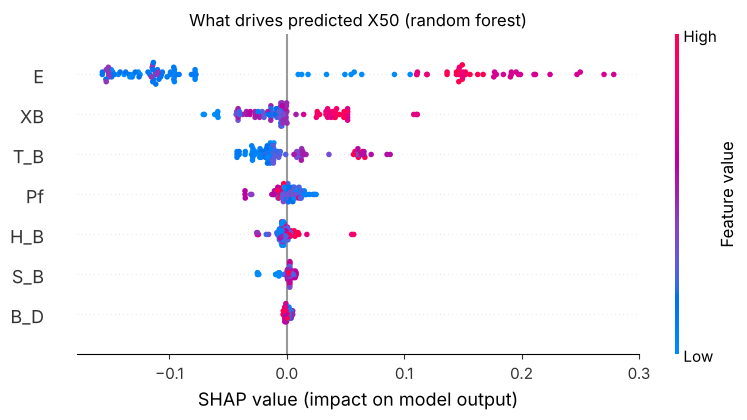

feature  mean |SHAP| (cm) direction in model physics expects
      E             13.11                  +        ? (mine)
     XB              2.76                  +               +
    T_B              2.50                  +               +
     Pf              0.77                  -               -
    H_B              0.58                  +               ?
    S_B              0.45                  +               ?
    B_D              0.17                  -               +


In [8]:
import shap

rf = models["random forest"].fit(X, y)
explainer = shap.TreeExplainer(rf)
sv = explainer.shap_values(X)

shap.summary_plot(sv, X, show=False)
plt.title("What drives predicted X50 (random forest)")
plt.tight_layout()
plt.show()

EXPECTED = {"Pf": "-", "B_D": "+", "XB": "+", "T_B": "+", "S_B": "?", "H_B": "?", "E": "? (mine)"}

check = []
for i, f in enumerate(FEATURES):
  rho = spearmanr(X[f], sv[:, i])[0]
  check.append({"feature": f, "mean |SHAP| (cm)": np.abs(sv[:, i]).mean()*100,
                "direction in model": "+" if rho > 0.1 else ("-" if rho < -0.1 else"flat"),
                "physics expects": EXPECTED[f]})

check = pd.DataFrame(check).sort_values("mean |SHAP| (cm)", ascending=False).round(2)
print(check.to_string(index=False))

**Findings**
- **E dominates** (about 13 cm average effect). Because E is constant inside each mine, this mostly means "the model recognises the mine". It is a difference *between* mines, not a lever a blaster can pull.
- **XB and T_B come next, both "+"** as physics expects: blockier rock and longer stemming give coarser fragments.
- **Powder factor points the right way ("−") but is tiny (0.8 cm).** This is the confounding from Step 2, now visible inside the model, and the reason Part B uses physics for explosive decisions.
- **B_D comes out "−"** where physics expects "+", but at 0.2 cm it is noise rather than a real effect.

**For a blast engineer:** the model's reasons mostly agree with physics, and where they do not, the cause is known.

## Step 5 · Calibrate Kuz-Ram for each rock class
The **Kuz-Ram** model (Cunningham, 1983) predicts median fragment size in **centimetres**:

$$X_{50} = A \cdot K^{-0.8} \cdot Q^{1/6} \cdot \left(\frac{115}{RWS}\right)^{19/30}$$

| Symbol | Meaning | In code |
|---|---|---|
| $A$ | rock factor: how hard the rock is to break (≈ 1–22) | `A_rock` |
| $K$ | powder factor (kg/m³) | `Pf` |
| $Q$ | explosive per hole (kg) | `Q` |
| $RWS$ | relative weight strength of the explosive (ANFO = 100) | `RWS` |

**Turning ratios into metres** (with the assumed hole diameter $D$ = 0.102 m):

$$B = (B/D)\cdot D \qquad S = (S/B)\cdot B \qquad H = (H/B)\cdot B$$

**Explosive per hole** = powder factor × rock volume broken by one hole:

$$Q = P_f \cdot B \cdot S \cdot H$$

**Explosive that fits in one metre of hole** (used in Step 6):

$$q = \rho_e \cdot \frac{\pi D^2}{4}$$

**Calibration.** $A$ is the only unknown. For each past blast we know the design and the measured X50, so we solve for $A$ by running Kuz-Ram with $A = 1$ and dividing:

$$A_i = \frac{X_{50,\,i}\ (\text{cm})}{\text{Kuz-Ram}(A{=}1,\ P_{f,i},\ Q_i)} \qquad\qquad A_{\text{site}} = \operatorname{median}(A_i)$$

The `× 100` converts X50 from metres to centimetres, because Kuz-Ram works in centimetres. The **median** resists one odd blast better than the mean. The function also returns the spread of $A_i$ and the error of calibrated Kuz-Ram at the site (MAE).

In [9]:
D_MM = A["hole_diameter"]
D_M = D_MM / 1000
RHO_E = A["explosive_density"]
RWS = A["explosive_RWS"]
q_per_m = RHO_E * np.pi * D_M**2 / 4  #kg of explosive per metre

def kuzram_X50_cm(A_rock, Pf, Q):
  """Median fragment size in cm."""
  return A_rock * Pf**-0.8 * Q**(1 / 6) * (115 / RWS)**(19 / 30)

def geometry(B_D, S_B, H_B):
  """Ratios -> metres , for the assumed hole diameter."""
  B = B_D * D_M
  return B, S_B * B, H_B * B

def site_A(site):
  g = df[df.site == site]
  B, S, H = geometry(g.B_D, g.S_B, g.H_B)
  Q = g.Pf * B * S * H  #kg per hole of explosive

  A_each = g.X50 * 100/ kuzram_X50_cm(1.0, g.Pf, Q)
  A_med = A_each.median()
  fit = kuzram_X50_cm(A_med, g.Pf, Q) / 100
  return A_med, A_each.min(), A_each.max(), mean_absolute_error(g.X50, fit) * 100

rocks[["A", "A_min", "A_max", "MAE_at_site_cm"]] = [site_A(s) for s in rocks.site]
print(rocks[["rock_class", "site", "E_GPa", "A", "A_min", "A_max", "MAE_at_site_cm"]].round(2))

  rock_class      site  E_GPa     A  A_min  A_max  MAE_at_site_cm
0       Soft  Akdaglar   16.9  7.32   4.24  12.79            5.12
1     Medium     Mrica   32.0  3.33   2.70   4.55            2.62
2       Hard    Murgul   50.0  9.87   8.88  13.34            3.67


**Findings**

| Rock class | Site | E (GPa) | A | A range | Kuz-Ram error at site |
|---|---|---|---|---|---|
| Soft | Akdaglar | 16.9 | 7.32 | 4.2 – 12.8 | 5.1 cm |
| Medium | Mrica | 32.0 | 3.33 | 2.7 – 4.6 | 2.6 cm |
| Hard | Murgul | 50.0 | 9.87 | 8.9 – 13.3 | 3.7 cm |

- Calibrated Kuz-Ram reproduces each site's blasts to within 3–5 cm.
- **A does not simply follow E.** Mrica (E = 32 GPa) breaks most easily (A = 3.3), while Akdaglar (E = 16.9) needs A = 7.3. Rock stiffness alone does not decide breakage; jointing, density and strength matter too, which is why A is calibrated from real blasts.
- Akdaglar's wide range (4.2–12.8) shows Kuz-Ram fits that quarry more loosely.

## Step 6 · Fragmentation and cost of any design
One function, `evaluate`, scores any design. **Bench height H is fixed** for each rock class (set by the mine plan), while burden, spacing and powder factor change around it.

**Geometry**

$$J = 0.3\,B \quad (\text{subdrill}) \qquad T = (T/B)_{\text{site}}\cdot B \quad (\text{stemming}) \qquad V = B \cdot S \cdot H$$

**Does the explosive fit in the hole?**

$$L_{\text{needed}} = \frac{Q}{q} \qquad L_{\text{free}} = H + J - T \qquad \text{fits if } L_{\text{needed}} \le L_{\text{free}}$$

**Fragment size:** Kuz-Ram from Step 5, with the site's calibrated $A$.

**Uniformity index** (Cunningham): how evenly sized the fragments are; low $n$ means many fines *and* many boulders.

$$n = \left(2.2 - \frac{14\,B}{D_{\text{mm}}}\right)\left(1 - \frac{W}{B}\right)\left(\frac{1 + S/B}{2}\right)\left(\frac{L}{H}\right)$$

with $W$ = drilling accuracy (0.2 m) and $L$ = charge length.

**Boulders** (Rosin–Rammler): the share of rock bigger than the oversize limit $x$ = 1 m.

$$\text{oversize} = \exp\!\left[-0.693\left(\frac{x}{X_{50}}\right)^{n}\right] \times 100\%$$

0.693 = ln 2, which makes exactly 50% of the rock smaller than X50.

**Cost per m³ of rock**

$$C = P_f \cdot c_{\text{exp}} + \frac{(H + J)\cdot c_{\text{drill}} + c_{\text{acc}}}{V}$$

explosive cost + (drilling the whole hole + detonator and booster) shared over the rock the hole breaks.

The loop at the end scores each site's **current** design (its median ratios) as a starting point.

In [10]:
def evaluate(Pf, B_D, S_B, rock, A_scale=1.0, c_exp=None, c_drill=None):
  c_exp = A["explosive_price"] if c_exp is None else c_exp
  c_drill = A["drilling_cost"] if c_drill is None else c_drill
  B = B_D * D_M
  S = S_B * B

  H = rock.bench_height_m   # bench height is fixed per rock class (from rock_types.csv)

  J = A["subdrill_ratio"] * B
  T = rock.T_B_median * B
  V = B * S * H
  Q = Pf * V
  L_needed = Q / q_per_m
  L_free = H + J - T
  X50 = kuzram_X50_cm(rock.A * A_scale, Pf, Q) / 100
  L = np.minimum(L_needed, L_free)
  n = ((2.2 - 14 * B / D_MM) * (1 - A["drilling_accuracy_W"] / B) * ((1 + S_B)/ 2)* (L/H))
  over = np.exp(-0.693 * (A["oversize_limit"] / X50) ** n) * 100
  cost = Pf * c_exp + ((H + J) * c_drill + A["accessories_per_hole"]) / V
  return dict(X50_cm = X50 * 100, oversize_pct = over, cost=cost, n=n,
              fits=L_needed <= L_free, H_B=H / B, Q_kg = Q)


for r in rocks.itertuples():
  e = evaluate(r.Pf_median, r.B_D_median, r.S_B_median, r)
  print(f"{r.rock_class:6s} {r.site:9s} current: X50 {e['X50_cm']:.0f} cm, "
        f"oversize {e['oversize_pct']:.1f}%, cost ${e['cost']:.2f}/m^3")

Soft   Akdaglar  current: X50 18 cm, oversize 0.5%, cost $3.76/m^3
Medium Mrica     current: X50 15 cm, oversize 0.0%, cost $1.67/m^3
Hard   Murgul    current: X50 30 cm, oversize 3.4%, cost $2.59/m^3


**Findings: current practice**

| Rock class | X50 now | Boulders | Cost now |
|---|---|---|---|
| Soft (Akdaglar) | 18 cm | 0.5% | $3.76/m³ |
| Medium (Mrica) | 15 cm | 0.0% | $1.67/m³ |
| Hard (Murgul) | 30 cm | 3.4% | $2.59/m³ |

Soft and medium rock already break well below the 30 cm target, so there is room to save. Hard rock sits right on the target.

## Step 7 · Cheapest design that meets the targets
**What this does:** a **grid search** tries every combination of powder factor (0.22–1.26 kg/m³ in steps of 0.01), B/D (25–39.5 in steps of 0.25) and S/B (1.0–1.5 in steps of 0.05), about 67,000 designs per rock class, scores each with `evaluate`, removes the ones that break a rule, and keeps the cheapest.

**Rules a design must pass**

$$X_{50} \le 30\ \text{cm} \qquad \text{oversize}_{>1\,\text{m}} \le 5\% \qquad L_{\text{needed}} \le L_{\text{free}} \qquad 2 \le H/B \le 6.82$$

and every input stays inside both the real data and the rules of thumb (B/D 25–40, S/B 1.0–1.5).

**Why grid search** rather than `scipy.optimize`: it is easy to read, shows the whole trade-off, and cannot get stuck in a local minimum.

**Boundary flag:** if the best design sits on the edge of the grid, that rule, not cost, is what limits it, and the design lies at the edge of the evidence.

In [11]:
PF_GRID = np.round(np.arange(df.Pf.min(), df.Pf.max() + 1e-9, 0.01), 2)
BD_GRID = np.round(np.arange(max(25, df.B_D.min()), min(40, df.B_D.max()) + 1e-9, 0.25), 2)
SB_GRID = np.round(np.arange(1.0, 1.5 + 1e-9, 0.05), 2)
PF, BD, SB = np.meshgrid(PF_GRID, BD_GRID, SB_GRID, indexing="ij")

def optimise(rock, **kw):
  e = evaluate(PF, BD, SB, rock, **kw)
  max_over_pct = A["max_oversize"]   # crash on purpose if the setting is missing
  ok = ((e["X50_cm"] <= A["target_X50"] * 100) & (e["oversize_pct"] <= max_over_pct)
        & e["fits"] & (e["H_B"] >= 2) & (e["H_B"] <= df.H_B.max()))
  if not ok.any():
    return None
  cost = np.where(ok, e["cost"], np.inf)
  i = np.unravel_index(np.argmin(cost), cost.shape)
  best = {k: float(np.asarray(v)[i]) for k, v in e.items()}
  best.update(Pf=PF[i], B_D=BD[i], S_B=SB[i])
  edges = []
  if PF[i] in (PF_GRID[0], PF_GRID[-1]): edges.append("Pf")
  if BD[i] in (BD_GRID[0], BD_GRID[-1]): edges.append("B/D")
  if SB[i] in (SB_GRID[0], SB_GRID[-1]): edges.append("S/B")
  best["on_boundary"] = ",".join(edges) or "no"
  return best

rec = []
for r in rocks.itertuples():
  now = evaluate(r.Pf_median, r.B_D_median, r.S_B_median, r)
  best = optimise(r)
  rec.append({
      "rock": f"{r.rock_class} ({r.site})",
      "Pf now": r.Pf_median, "Pf best": best["Pf"],
      "B/D now": r.B_D_median, "B/D best": best["B_D"],
      "S/B now": r.S_B_median, "S/B best": best["S_B"],
      "fits now": bool(now["fits"]),
      "X50 now (cm)": now["X50_cm"], "X50 best (cm)": best["X50_cm"],
      "boulders best (%)": best["oversize_pct"],
      "cost now ($/m³)": now["cost"], "cost best ($/m³)": best["cost"],
      "saving (%)": (1 - best["cost"] / now["cost"]) * 100,
      "on boundary": best["on_boundary"],
  })
rec = pd.DataFrame(rec).round(2)
print(rec.T)
rec.to_csv(RESULTS + "recommended_designs.csv", index=False)

                                 0               1              2
rock               Soft (Akdaglar)  Medium (Mrica)  Hard (Murgul)
Pf now                        0.76            0.45           0.61
Pf best                       0.42            0.22           0.61
B/D now                      22.47           32.89           30.3
B/D best                      27.5           39.25          25.75
S/B now                       1.14             1.2            1.0
S/B best                      1.45             1.5           1.35
fits now                      True            True          False
X50 now (cm)                 18.36           15.35          29.99
X50 best (cm)                29.75           26.59          29.86
boulders best (%)             2.03            0.67           0.68
cost now ($/m³)               3.76            1.67           2.59
cost best ($/m³)              2.02            0.91           2.61
saving (%)                   46.32           45.43          -0.79
on boundar

**Recommended designs**

| | Soft (Akdaglar) | Medium (Mrica) | Hard (Murgul) |
|---|---|---|---|
| Powder factor now → best (kg/m³) | 0.76 → **0.42** | 0.45 → 0.22 | 0.61 → **0.61** |
| B/D now → best | 22.5 → **27.5** | 32.9 → 39.3 | 30.3 → **25.8** |
| S/B now → best | 1.14 → **1.45** | 1.20 → 1.50 | 1.00 → **1.35** |
| X50 best | 29.8 cm | 26.6 cm | 29.9 cm |
| Boulders best | 2.0% | 0.7% | 0.7% |
| Cost now → best ($/m³) | 3.76 → **2.02** | 1.67 → 0.91 | 2.59 → **2.61** |
| Saving | **46%** | 45% | −1% |
| On a boundary? | no | **Pf, B/D, S/B** | no |

- **Soft (Akdaglar):** a 30 cm target allows much less explosive and a wider pattern, for a **46% saving**. Akdaglar is an aggregate quarry, however, and may *want* small rock, so the right target depends on the product being sold.
- **Medium (Mrica):** the "best" design sits on **three boundaries at once** (lowest powder factor in the data, widest pattern allowed). The optimiser has run to the edge of the evidence: treat it as a direction for **field trials**, not a recommendation.
- **Hard (Murgul):** the current design **does not fit** a 102 mm hole with ANFO ("fits now" = False): it needs about 6.2 m of charge but only about 5.9 m is free below the stemming. Murgul must therefore use larger holes or a denser explosive. The recommended design keeps X50 at 30 cm with a charge that fits, at about the same cost.

## Step 8 · Sensitivity: what if the rock or prices change?
**What this does:** re-runs the optimiser under six scenarios and reports the change in the cheapest cost:

$$\Delta C\,(\%) = \left(\frac{C_{\text{scenario}}}{C_{\text{base}}} - 1\right)\times 100$$

| Scenario | Change made |
|---|---|
| Rock 10% harder | rock factor $A \times 1.10$ |
| Explosive ±20% | $c_{\text{exp}} \times 1.2$ or $\times 0.8$ |
| Drilling ±20% | $c_{\text{drill}} \times 1.2$ or $\times 0.8$ |

**Why:** it answers the brief's question ("if rock gets 10% harder, how much does cost go up?") and shows which assumption the answer depends on most.

In [12]:
scenarios = {
    "base": {},
    "rock 10% harder": {"A_scale": 1.10},
    "explosive +20%": {"c_exp": A["explosive_price"] * 1.2},
    "explosive -20%": {"c_exp": A["explosive_price"] * 0.8},
    "drilling +20%": {"c_drill": A["drilling_cost"] * 1.2},
    "drilling -20%": {"c_drill": A["drilling_cost"] * 0.8},
}
sens = []
for r in rocks.itertuples():
    base = optimise(r)["cost"]
    for name, kw in scenarios.items():
        b = optimise(r, **kw)
        sens.append({"rock": r.rock_class, "scenario": name,
                     "cost ($/m^3)": b["cost"] if b else np.nan,
                     "change vs base (%)": (b["cost"] / base - 1) * 100 if b else np.nan,
                     "Pf": b["Pf"] if b else np.nan,
                     "B/D": b["B_D"] if b else np.nan})
sens = pd.DataFrame(sens).round(2)
print(sens.pivot(index="scenario", columns="rock", values="change vs base (%)")
          .reindex(list(scenarios)))
sens.to_csv(RESULTS + "sensitivity.csv", index=False)

rock              Hard  Medium   Soft
scenario                             
base              0.00    0.00   0.00
rock 10% harder  12.36    0.00  10.15
explosive +20%    4.67    4.82   4.17
explosive -20%   -4.67   -4.82  -4.17
drilling +20%    13.66   14.50  14.32
drilling -20%   -13.66  -14.50 -14.32


**Findings**

| Scenario | Soft | Medium | Hard |
|---|---|---|---|
| Rock 10% harder | **+10.2%** | 0.0% | **+12.4%** |
| Explosive +20% | +4.2% | +4.8% | +4.7% |
| Drilling +20% | +14.3% | +14.5% | +13.7% |

- **10% harder rock raises cost by 10–12%** for soft and hard rock. Medium rock shows 0% because its optimum was already on the boundaries with X50 well under 30 cm, so harder rock changes nothing there.
- **Drilling price matters about three times more than explosive price.** Drilling is the larger share of cost at these patterns, so it is the price to confirm with the mine first.

## Conclusions
1. **Rock properties drive fragmentation more than design does.** Rock stiffness and block size explain most of the difference in fragment size between mines (SHAP); design changes act within that.
2. **Machine learning predicts well at known mines but not at new ones.** The best models reach R² ≈ 0.78 (about ±6 cm) on new blasts at known mines but fall to R² ≈ 0.15 at best on an unseen mine. A new site needs its own calibration blasts before any model is trusted there.
3. **The data cannot measure the effect of explosive within a mine.** Engineers load more where rock is tough, so powder factor and difficulty are confounded. Explosive decisions were therefore made with Kuz-Ram, calibrated to each mine (rock factor A = 7.3, 3.3 and 9.9 for soft, medium and hard rock, reproducing site blasts to within 3–5 cm).
4. **For a 30 cm target with ≤ 5% boulders:**
    - **Soft rock** can save about **46%** (powder factor 0.76 → 0.42 kg/m³, wider pattern), if the product allows coarser rock.
    - **Medium rock** points the same way, but the result lies at the edge of the data and needs field trials.
    - **Hard rock** is already at the target; its current design does not fit a 102 mm ANFO charge, so the recommended design mainly makes the charge fit.
5. **Sensitivity:** 10% harder rock raises the cheapest cost by about 10–12%; drilling price moves cost three times more than explosive price.

### Limitations
- 110 blasts from published papers; three rock classes are each represented by a single mine.
- One assumed hole diameter (102 mm) and assumed prices; real values differ by mine.
- Kuz-Ram is an empirical model with its own error (3–5 cm here) and predicts the median size better than the tails of the size distribution.
- No flyrock, vibration or downstream crushing and grinding costs are included, and lower fragmentation targets can raise crushing costs.
- Recommendations are starting points for field trials, not designs to fire directly.

### Next steps
- Calibrate on a real mine's blast records with measured hole diameters and fragmentation images.
- Add crusher and mill energy to the cost, to find the fragmentation that minimises **total** mine-to-mill cost.
- Add vibration and flyrock limits (scaled distance and PPV) as constraints in the optimiser.